# Figure showing the mean change in an impact variable

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import warnings
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
import matplotlib as mpl
from matplotlib import patches as mpatches
from cartopy import crs as ccrs
import cmocean

from funcs_support import get_filepaths,get_params,utility_print
from funcs_readregs import coeffs_mortality,coeffs_gdppc,coeffs_payroll
from funcs_plot import plot_map
dir_list = get_params()

In [2]:
from distributed import Client

# Start dask client 
client = Client()
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 44271 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/44271/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/44271/status,Workers: 6
Total threads: 18,Total memory: 72.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43831,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/44271/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38873,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/45471/status,Memory: 12.00 GiB
Nanny: tcp://127.0.0.1:41123,


In [3]:
# Get filenames of impact projections
fns = get_filepaths(source_dir = 'impacts',dir_list = {'impacts':dir_list['proc']+'impact_projs/'})
fns = fns.query('freq == "agg"')
fns = fns.iloc[['crossfit' not in var for var in fns.varname.values]]
fns = fns.set_index(['varname','model']).sort_index()

In [4]:

params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'mortality-interacted':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}

imp_params = {'dmortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'dmortality-interacted':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'dgdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'dpayroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}


nruns = {'dmortality':13,
         'dmortality-interacted':13,
         'dgdppc':13,
         'dpayroll':10}


In [5]:
cbar_params = {'mean':{'dmortality':{'vmin':-100,'vmax':100,'cmap':cmocean.cm.balance},
                   'dmortality-interacted':{'vmin':-100,'vmax':100,'cmap':cmocean.cm.balance},
                   'dgdppc':{'vmin':-10,'vmax':10,'cmap':cmocean.cm.balance},
                   'dpayroll':{'vmin':-0.016,'vmax':0,'cmap':cmocean.cm.amp_r}},
               'std':{'dmortality':{'vmin':0,'vmax':50,'cmap':cmocean.cm.tempo},
                   'dmortality-interacted':{'vmin':0,'vmax':50,'cmap':cmocean.cm.tempo},
                   'dgdppc':{'vmin':0,'vmax':10,'cmap':cmocean.cm.tempo},
                   'dpayroll':{'vmin':0,'vmax':0.008,'cmap':cmocean.cm.tempo}}}

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: /glade/u/home/schwarzwald/projects/impact_uncertainty/aux_data/geo_data/impact-region.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for s

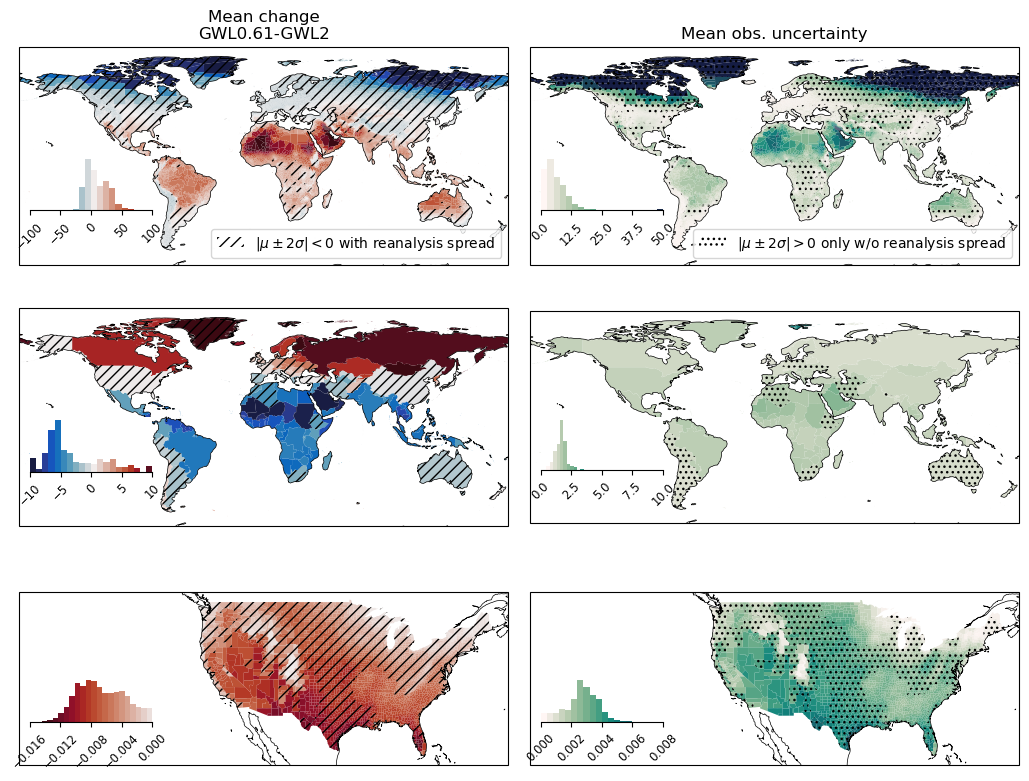

In [171]:
gwl = 2
keep_idvs_ref_gwl = 2

fig = plt.figure(figsize=(19.5,13))
gs = plt.GridSpec(nrows=len(params_proc),
                  ncols=3*4)

for row_idx,var in enumerate(['dmortality','dgdppc','dpayroll']):
    proc = re.sub(r'^d','',var)
    #---------------------------
    # Load impact data ---------
    #---------------------------
    dss = []
    for row in fns.loc[var].iterrows():
        with warnings.catch_warnings():
            # .done flag warning in zarr opening
            warnings.filterwarnings('ignore')
            ds_tmp = xr.open_zarr(row[1]['path'],consolidated=False)
        if ds_tmp.sizes['idv'] < nruns[var]:
            continue
        else:
            ds_tmp = ds_tmp.sel(imp_params[var],drop=True)
            
            # Drop all-na idvs
            keep_idvs = ds_tmp.sel(gwl=keep_idvs_ref_gwl).dropna('idv',how='all').idv
            ds_tmp = ds_tmp.sel(idv = keep_idvs.values)
            # Get the first x runs
            ds_tmp = ds_tmp.isel(idv = slice(0,nruns[var]))
    
            if ds_tmp.sizes['idv']<nruns[var]:
                continue
            
            # Get mean over different obs products
            #ds_tmp = ds_tmp.mean(('proj_base'))
            ds_tmp['exprun'] = ds_tmp['experiment'].load()+ds_tmp['run'].load()
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        
            dss.append(ds_tmp)
            
    # Concat
    dss = xr.concat(dss,
                    dim='idv',
                    join='outer',
                    data_vars='minimal').load()
    
    dss['poly_idx'] = dss['locid']
    dss = dss.drop_vars('locid').rename({'poly_idx':'locid'})

    # Get locs with significant changes under obs uncertainty 
    # and without obs uncertainty (defined as mean +/- 2std 
    # diff from 0)
    sig_wobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).std(('proj_base','idv')) > 0)
    sig_noobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).mean('proj_base').std(('idv')) > 0)
    sigs = sig_wobs.astype(int)+sig_noobs.astype(int)

    
    #-------------------------------
    # Load corresponding shapefile -
    #-------------------------------
    # Load shapefile
    gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
    gdf['geometry'] = gdf.make_valid()
    
    # Name merging dimension 'locid'
    gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)
    
    # Remove locs if necessary
    if params_proc[proc]['geo_typ'] == 'impact-regions':
        # Remove Antarctica
        gdf = gdf.query('ISO != "ATA"')
    elif params_proc[proc]['geo_typ'] == 'adm1':
        gdf = gdf.query('locid != "Antarctica"')
    elif params_proc[proc]['geo_typ'] == 'adm2-us':
        # Remove Alaska and Hawaii
        gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]

    #-------------------------------
    # Plot -------------------------
    #-------------------------------
    for col_idx,plot_typ in zip(np.arange(1,3),['mean','std']):
        #if params_proc[proc]['geo_typ'] == 'adm2-us':
        #    # Only use part of the horizontal grid spec for the smaller counties map
        #    ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=ccrs.PlateCarree())
        #else: 
        ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=ccrs.PlateCarree())

        if plot_typ == 'mean':
            plot_data = dss[var].sel(gwl=gwl).mean(('proj_base','idv'))
        elif plot_typ == 'std':
            plot_data = dss[var].sel(gwl=gwl).std('proj_base').mean('idv')
            
        fig,ax = plot_map(plot_data.sel(locid = gdf.locid.values),
             gdf,**cbar_params[plot_typ][var],fig=fig,ax=ax_map)

        # Plot hatching
        gdf_tmp = gdf.copy()
        sigs = sigs.sel(locid = gdf_tmp.locid.values)
        if plot_typ == 'mean':
            gdf_tmp['tohatch'] = (sigs < 2)
            hatch = '///'
            label = r'$|\mu \pm 2\sigma|<0$ with reanalysis spread' 
        elif plot_typ == 'std':
            gdf_tmp['tohatch'] = (sigs == 1)
            hatch = '...'
            label = r'$|\mu \pm 2\sigma|>0$ only w/o reanalysis spread'
        gdf_tmp = gdf_tmp.where(gdf_tmp.tohatch).dissolve()
        gdf_tmp.plot(facecolor='none',
                     edgecolor='black',linewidth=0, # doesn't plot with no edgecolor
                     hatch=hatch,
                     ax=ax_map)
        if row_idx == 0:
            ax.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                               hatch=hatch, label=label)],
                      loc = 'lower right')
    
        ax.coastlines(linewidth=0.5)

        if row_idx == 0:
            ax.set_title(col_titles[plot_typ])
        else:
            ax.set_title('')

        if var == 'dpayroll':
            ax.set_extent((-160, -64, 23.7, 50.6),
                          crs = ccrs.PlateCarree())


        # Inset colorbar histogram
        nbins = 20
        ax = ax_map.inset_axes([0.0225, 0.25, 0.25, 0.25], xticks=[], yticks=[])
        
        N, bins, patches = (plot_data.clip(min=cbar_params[plot_typ][var]['vmin'],
                                           max=cbar_params[plot_typ][var]['vmax']).
                            plot.hist(bins=nbins,ax=ax))
        
        for binid, patch in enumerate(patches):
            patch.set_facecolor(cbar_params[plot_typ][var]['cmap'](np.arange(0,1,1/nbins))[binid,:])
        
        for side in ['top','left','right']:
            ax.spines[side].set_visible(False)
        ax.set_title('')
        ax.set_xticks(np.arange(cbar_params[plot_typ][var]['vmin'],
                                cbar_params[plot_typ][var]['vmax']+0.0000001,
                                (cbar_params[plot_typ][var]['vmax'] - 
                                 cbar_params[plot_typ][var]['vmin'])/4))
        ax.set_xlim(cbar_params[plot_typ][var]['vmin'],
                    cbar_params[plot_typ][var]['vmax'])
        ax.set_yticks([])
        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.set_title('')
        ax.tick_params(axis='x',labelrotation=45,labelsize='small')


In [7]:
nsamples = 1000
rng = np.random.default_rng()

colors = {'ERA5':'tab:red','JRA-3Q':'tab:orange','MERRA2':'tab:green','GMFD':'tab:blue','PRISM':'yellow','UDel':'yellow'}

#proc_names = {'mortality':'mortality rate [/100,000]',
#              'gdppc':'log GDP per capita growth',
#              'payroll':'payroll'}
proc_names = {'mortality':r'$\bf{Carleton\ et\ al.\ (2022)}$'+'\nmortality rate [/100,000]',
              'gdppc':r'$\bf{BHM\ (2015)}$'+'\nlog GDP per capita growth',
              'payroll':r'$\bf{Behrer\ et\ al.\ (2021)}$'+'\npayroll'}
proc_titles = {'mortality':'annual mortality rate',
               'gdppc':'GDP per capita growth',
               'payroll':'annual payroll'}
proc_xlims = {'mortality':[-15,45],
              'gdppc':[-2.5,32.5],
              'payroll':[70,115]}
proc_ylims = {'mortality':[-1,8],
              'gdppc':[-0.375,0.025],
              'payroll':[-0.00075,0.0001]}

def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

def plot_dmgfs(dmgf,proc,ax=None,
               colors = colors,
               add_grid = True,
               proc_names = proc_names,
               proc_titles = proc_titles,
               proc_xlims = proc_xlims,
               proc_ylims = proc_ylims,
               simple = False):
    '''
    Damage function plotting code 

    '''

    if ax is None:
        ax = plt.subplot()
    
    for proj_base in dmgf.proj_base.values:
        plot_data = dmgf.sel(proj_base = proj_base)
        ax.fill_between(plot_data.Tref,
                        plot_data.quantile(0.025,dim='sidx'),
                        plot_data.quantile(0.975,dim='sidx'),
                        color=colors[proj_base],alpha=0.1)
        plot_data.mean('sidx').plot(color=colors[proj_base],linewidth=1,label=proj_base)
    
    
    ax.set_xlim(proc_xlims[proc])
    ax.set_ylim(proc_ylims[proc])

    if not simple:
        if add_grid:
            plt.grid()

    if simple:
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_title('')
    else:    
        ax.set_xlabel(r'Temperature')# [$^\circ$C]')
        ax.set_ylabel('Change in\n'+proc_names[proc])
        ax.set_title('Impact of day at T on\n'+proc_titles[proc])

    ax.axhline(0,color='k',linewidth=1)

    return ax 

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/sit

TypeError: Bbox.from_bounds() takes 4 positional arguments but 11 were given

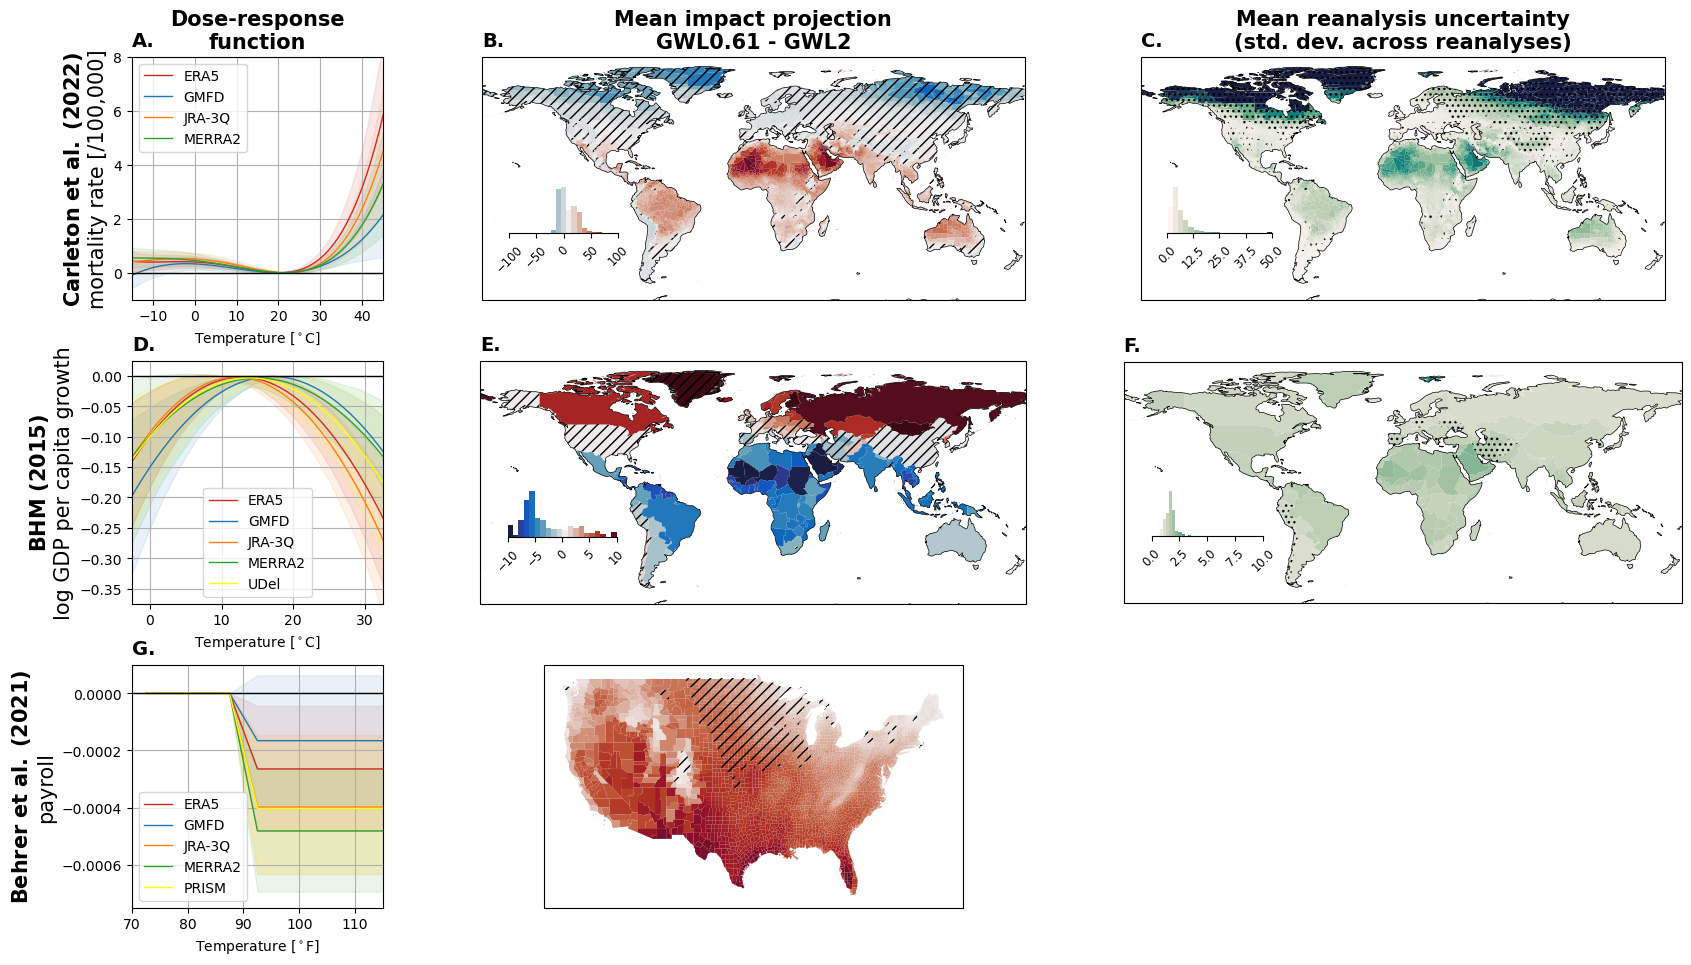

In [8]:
gwl = 2
keep_idvs_ref_gwl = 2
save_fig = True

for spread_typ in ['iqr','2sd']:

    output_fn = f'{dir_list['figs']}extra_figs/Figure1_alt_wmaps_spread{spread_typ}'
    
    col_titles = {'mean':'Mean impact projection\nGWL0.61 - GWL'+str(gwl),
                  'std':'Mean reanalysis uncertainty\n(std. dev. across reanalyses)'}
    
    fig = plt.figure(figsize=(20,15))
    gs = plt.GridSpec(nrows=len(params_proc),
                      ncols=3,
                      width_ratios = [0.45,1,1],
                      hspace = 0.25)
    
    for row_idx,var in enumerate(['dmortality','dgdppc','dpayroll']):
        proc = re.sub(r'^d','',var)
    
        #---------------------------
        # Plot damage function -----
        #---------------------------
        dmgf = load_dmgfs(proc)
    
        ax = fig.add_subplot(gs[row_idx,0])
    
        ax = plot_dmgfs(dmgf,proc,ax=ax)
    
        ax.annotate(string.ascii_uppercase[row_idx*3]+'.',(0,1.025),xycoords = 'axes fraction',
                    va = 'bottom',fontweight='bold',fontsize=14)
    
        ax.legend()
    
        if row_idx == 0:
            ax.set_title('Dose-response\nfunction',fontsize=15,fontweight='bold')
        else:
            ax.set_title('')
    
        if proc in ['mortality','gdppc']:
            ax.set_xlabel(r'Temperature [$^\circ$C]')
        elif proc in ['payroll']:
            ax.set_xlabel(r'Temperature [$^\circ$F]')
    
        ax.set_ylabel(proc_names[proc],fontsize=15)
        
    
        
        #---------------------------
        # Load impact data ---------
        #---------------------------
        dss = []
        for row in fns.loc[var].iterrows():
            with warnings.catch_warnings():
                # .done flag warning in zarr opening
                warnings.filterwarnings('ignore')
                ds_tmp = xr.open_zarr(row[1]['path'],consolidated=False)
            if ds_tmp.sizes['idv'] < nruns[var]:
                continue
            else:
                ds_tmp = ds_tmp.sel(imp_params[var],drop=True)
                
                # Drop all-na idvs
                keep_idvs = ds_tmp.sel(gwl=keep_idvs_ref_gwl).dropna('idv',how='all').idv
                ds_tmp = ds_tmp.sel(idv = keep_idvs.values)
                # Get the first x runs
                ds_tmp = ds_tmp.isel(idv = slice(0,nruns[var]))
        
                if ds_tmp.sizes['idv']<nruns[var]:
                    continue
                
                # Get mean over different obs products
                #ds_tmp = ds_tmp.mean(('proj_base'))
                ds_tmp['exprun'] = ds_tmp['experiment'].load()+ds_tmp['run'].load()
                ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            
                dss.append(ds_tmp)
                
        # Concat
        dss = xr.concat(dss,
                        dim='idv',
                        join='outer',
                        data_vars='minimal').load()
        
        dss['poly_idx'] = dss['locid']
        dss = dss.drop_vars('locid').rename({'poly_idx':'locid'})
    
        # Get locs with significant changes under obs uncertainty 
        # and without obs uncertainty (defined as mean +/- 2std 
        # diff from 0)
        if spread_typ == '2sd':
            sig_wobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).std(('proj_base','idv')) > 0)
            sig_noobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).mean('proj_base').std(('idv')) > 0)
        elif spread_typ == 'iqr':
            d = dss[var].sel(gwl=gwl)
            sig_wobs = d.quantile(0.025,('proj_base','idv'))/np.abs(d.quantile(0.025,('proj_base','idv'))) == d.quantile(0.975,('proj_base','idv'))/np.abs(d.quantile(0.975,('proj_base','idv')))
            sig_noobs = d.mean('proj_base').quantile(0.025,('idv'))/np.abs(d.mean('proj_base').quantile(0.025,('idv'))) == d.mean('proj_base').quantile(0.975,('idv'))/np.abs(d.mean('proj_base').quantile(0.975,('idv')))
    
        sigs = sig_wobs.astype(int)+sig_noobs.astype(int)
    
        
        #-------------------------------
        # Load corresponding shapefile -
        #-------------------------------
        # Load shapefile
        gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['shp_fn']}.shp')
        gdf['geometry'] = gdf.make_valid()
        
        # Name merging dimension 'locid'
        gdf = gdf.rename(idxs[params_proc[proc]['geo_typ']],axis=1)
        
        # Remove locs if necessary
        if params_proc[proc]['geo_typ'] == 'impact-regions':
            # Remove Antarctica
            gdf = gdf.query('ISO != "ATA"')
        elif params_proc[proc]['geo_typ'] == 'adm1':
            gdf = gdf.query('locid != "Antarctica"')
        elif params_proc[proc]['geo_typ'] == 'adm2-us':
            # Remove Alaska and Hawaii
            gdf = gdf.iloc[[sn not in ['Alaska','Hawaii'] for sn in gdf.STATE_NAME.values]]
    
        #-------------------------------
        # Plot -------------------------
        #-------------------------------
        for col_idx,plot_typ in zip(np.arange(1,3),['mean','std']):
            #if params_proc[proc]['geo_typ'] == 'adm2-us':
            #    # Only use part of the horizontal grid spec for the smaller counties map
            #    ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=ccrs.PlateCarree())
            #else: 
            #ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=ccrs.PlateCarree())
            ax_map = fig.add_subplot(gs[row_idx,col_idx],projection=ccrs.PlateCarree())
    
            if plot_typ == 'mean':
                plot_data = dss[var].sel(gwl=gwl).mean(('proj_base','idv'))
            elif plot_typ == 'std':
                plot_data = dss[var].sel(gwl=gwl).std('proj_base').mean('idv')
                
            fig,ax = plot_map(plot_data.sel(locid = gdf.locid.values),
                 gdf,**cbar_params[plot_typ][var],fig=fig,ax=ax_map)
    
            # Plot hatching
            gdf_tmp = gdf.copy()
            sigs = sigs.sel(locid = gdf_tmp.locid.values)
            if plot_typ == 'mean':
                gdf_tmp['tohatch'] = (sigs < 2)
                hatch = '///'
                if spread_typ == 'iqr':
                    label = r'>95% of runs, reanalyses with same sign change' 
                elif spread_typ == '2sd':
                    label = r'$|\mu \pm 2\sigma|<0$ with reanalysis spread'
                    
            elif plot_typ == 'std':
                gdf_tmp['tohatch'] = (sigs == 1)
                hatch = '...'
                if spread_typ == 'iqr':
                    label = r'>95% of runs with same sign change only when assuming no rea. unc.'
                elif spread_typ == '2sd':
                    label = r'$|\mu \pm 2\sigma|>0$ only w/o reanalysis spread'
                    
            gdf_tmp = gdf_tmp.where(gdf_tmp.tohatch).dissolve()
            gdf_tmp.plot(facecolor='none',
                         edgecolor='black',linewidth=0, # doesn't plot with no edgecolor
                         hatch=hatch,
                         ax=ax_map)
            if row_idx == 2:
                ax.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                                   hatch=hatch, label=label)],
                          bbox_to_anchor = 'lower right')
        
            ax.coastlines(linewidth=0.5)
    
            if row_idx == 0:
                ax.set_title(col_titles[plot_typ],fontsize=15,fontweight='bold')
            else:
                ax.set_title('')
    
            if var == 'dpayroll':
                ax.set_extent((-142.5, -64, 23.7, 50.6),
                              crs = ccrs.PlateCarree())
        
            # Inset colorbar histogram
            nbins = 20
            ax = ax_map.inset_axes([0.05, 0.275, 0.2, 0.2], xticks=[], yticks=[])
            
            N, bins, patches = (plot_data.clip(min=cbar_params[plot_typ][var]['vmin'],
                                               max=cbar_params[plot_typ][var]['vmax']).
                                plot.hist(bins=nbins,ax=ax))
            
            for binid, patch in enumerate(patches):
                patch.set_facecolor(cbar_params[plot_typ][var]['cmap'](np.arange(0,1,1/nbins))[binid,:])
            
            for side in ['top','left','right']:
                ax.spines[side].set_visible(False)
            ax.set_title('')
            ax.set_xticks(np.arange(cbar_params[plot_typ][var]['vmin'],
                                    cbar_params[plot_typ][var]['vmax']+0.0000001,
                                    (cbar_params[plot_typ][var]['vmax'] - 
                                     cbar_params[plot_typ][var]['vmin'])/4))
            ax.set_xlim(cbar_params[plot_typ][var]['vmin'],
                        cbar_params[plot_typ][var]['vmax'])
            ax.set_yticks([])
            ax.set_ylabel('')
            ax.set_xlabel('')
            ax.set_title('')
            ax.tick_params(axis='x',labelrotation=45,labelsize='small')
    
            # Subplot labeling
            ax_map.annotate(string.ascii_uppercase[row_idx*3+col_idx]+'.',(0,1.025),xycoords = 'axes fraction',
                                        va = 'bottom',fontweight='bold',fontsize=14)

    if save_fig:
        utility_print(output_fn)
